# Práce s rastrovými daty v knihovně `rasterio`

V tomto notebooku si projdeme základní rastrové postupy v dálkovém průzkumu Země (DPZ) nad daty **Sentinel-2 Level-2A** v knihovně **`rasterio`**:

- vyhledání málo oblačné scény přes STAC katalog a kontrolu prostorových metadat,
- načtení ohraničeného výřezu pomocí oken (`Window`) a převod hodnot na odrazivost,
- sjednocení vrstev s různým rozlišením na společnou mřížku (`reproject`),
- vizualizaci kompozic True Color a False Color,
- maskování oblačnosti podle vrstvy `SCL` a výpočet indexů **NDVI** a **NDBI**,
- tvorbu masek vegetace, zástavby a vody,
- porovnání NDVI napříč třídami povrchů a rozloha v území

In [1]:
!pip install -q rasterio pystac-client planetary-computer matplotlib numpy

In [2]:
import os
import numpy as np
import rasterio
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds, transform_geom, reproject, Resampling
from rasterio.mask import mask
from rasterio.io import MemoryFile
import pystac_client
import planetary_computer as pc
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

## 1. Vyhledání scény a kontrola metadat v `rasterio`

Přes STAC API vyhledáme letní scénu **Sentinel-2 Level-2A** s nízkou oblačností pro zájmové území v severní části Prahy (okolí Stromovky a Vltavy). Otevřením rastru přes `rasterio.open()` si ověříme souřadnicový systém, rozsah, rozměry, velikost pixelu a afinní transformaci.

In [3]:
# Vymezení zájmového území (WGS84 / EPSG:4326) a vyhledání scény Sentinel-2 L2A
bbox_wgs84 = [14.402, 50.098, 14.432, 50.118]

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=pc.sign_inplace,
)

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=bbox_wgs84,
    datetime="2023-05-01/2023-08-31",
    query={"eo:cloud_cover": {"lt": 15}},
)

items = list(search.items())
print(f"Nalezeno scén: {len(items)}")

item = items[0]
print("ID scény:", item.id)
print("Datum pořízení:", item.datetime)
print("Oblačnost (%):", item.properties.get("eo:cloud_cover"))

Nalezeno scén: 19
ID scény: S2B_MSIL2A_20230823T095559_R122_T33UVR_20241019T191513
Datum pořízení: 2023-08-23 09:55:59.024000+00:00
Oblačnost (%): 14.960556


In [4]:
# Kontrola prostorových metadat rastru pomocí rasterio.open()
href_b08 = item.assets["B08"].href

with rasterio.open(href_b08) as src:
    print("Souřadnicový systém (CRS):", src.crs)
    print("Rozsah v jednotkách CRS:", src.bounds)
    print("Rozměry rastru (řádky x sloupce):", src.height, src.width)
    print("Velikost pixelu (šířka, výška):", src.res)
    print("Datový typ:", src.dtypes[0])
    print("Transformační matice:\n", src.transform)

Souřadnicový systém (CRS): EPSG:32633
Rozsah v jednotkách CRS: BoundingBox(left=399960.0, bottom=5490240.0, right=509760.0, top=5600040.0)
Rozměry rastru (řádky x sloupce): 10980 10980
Velikost pixelu (šířka, výška): (10.0, 10.0)
Datový typ: uint16
Transformační matice:
 | 10.00, 0.00, 399960.00|
| 0.00,-10.00, 5600040.00|
| 0.00, 0.00, 1.00|


## 2. Načtení výřezu přes `Window` a kalibrace pásem

Při práci s družicovými snímky je praktické načíst jen potřebný výřez místo celé granule. Pomocí `transform_bounds`, `from_bounds` a `Window` načteme 10m pásma **B02** (modré), **B03** (zelené), **B04** (červené) a **B08** (blízké infračervené – NIR) a dále 20m vrstvy **B11** (krátkovlnné infračervené – SWIR) a **SCL** (*Scene Classification Layer*).

U produktů Sentinel-2 L2A převádíme digitální hodnoty na odrazivost vztahem `(DN - 1000) / 10000`.

In [5]:
# Načtení výřezu konkrétního pásma přes rasterio Window
def nacti_okno(asset_key, bbox_4326):
    href = item.assets[asset_key].href
    with rasterio.open(href) as src:
        bbox_crs = transform_bounds("EPSG:4326", src.crs, *bbox_4326)
        win = from_bounds(*bbox_crs, transform=src.transform).round_offsets().round_lengths()
        arr = src.read(1, window=win)
        win_transform = src.window_transform(win)
        crs = src.crs
        res = src.res
    return arr, win_transform, crs, res

In [6]:
# Načtení výřezů pěti spektrálních pásem a klasifikační vrstvy SCL
b02_raw, win_transform_10m, crs, res_10m = nacti_okno("B02", bbox_wgs84)
b03_raw, _, _, _ = nacti_okno("B03", bbox_wgs84)
b04_raw, _, _, _ = nacti_okno("B04", bbox_wgs84)
b08_raw, _, _, _ = nacti_okno("B08", bbox_wgs84)

b11_20m_raw, win_transform_20m, _, res_20m = nacti_okno("B11", bbox_wgs84)
scl_20m, _, _, _ = nacti_okno("SCL", bbox_wgs84)

print("Rozměr 10m výřezu (řádky x sloupce):", b08_raw.shape, "| rozlišení:", res_10m)
print("Rozměr 20m výřezu (řádky x sloupce):", b11_20m_raw.shape, "| rozlišení:", res_20m)

Rozměr 10m výřezu (řádky x sloupce): (224, 216) | rozlišení: (10.0, 10.0)
Rozměr 20m výřezu (řádky x sloupce): (112, 108) | rozlišení: (20.0, 20.0)


In [7]:
# Převod spektrálních pásem na odrazivost
def kalibruj(pasmo):
    return (pasmo.astype("float32") - 1000.0) / 10000.0

b02 = kalibruj(b02_raw)
b03 = kalibruj(b03_raw)
b04 = kalibruj(b04_raw)
b08 = kalibruj(b08_raw)
b11_20m = kalibruj(b11_20m_raw)

print(f"Ukázka kalibrace B08 [0, 0]: surové {b08_raw[0, 0]} -> odrazivost {b08[0, 0]:.4f}")

Ukázka kalibrace B08 [0, 0]: surové 3020 -> odrazivost 0.2020


## 3. Sjednocení rozlišení na 10m mřížku

Pásmo **B11** a vrstva **SCL** mají rozlišení 20 m, zatímco **B04** a **B08** mají rozlišení 10 m. Funkcí `rasterio.warp.reproject()` převedeme **B11** (bilineárním převzorkováním) a **SCL** (nejbližším sousedem, aby zůstaly zachovány kódy tříd) na přesnou geometrii 10m výřezu.

In [8]:
# Převzorkování rastru na cílovou 10m mřížku pomocí rasterio.warp.reproject()
def na_10m_mrizku(zdroj_arr, zdroj_transform, metoda_resampling, vystup_dtype):
    cil_arr = np.empty(b08.shape, dtype=vystup_dtype)
    reproject(
        source=zdroj_arr,
        destination=cil_arr,
        src_transform=zdroj_transform,
        src_crs=crs,
        dst_transform=win_transform_10m,
        dst_crs=crs,
        resampling=metoda_resampling,
    )
    return cil_arr

In [9]:
# Sjednocení pásem B11 a vrstvy SCL na 10m výřez
b11 = na_10m_mrizku(b11_20m, win_transform_20m, Resampling.bilinear, "float32")
scl = na_10m_mrizku(scl_20m.astype("int16"), win_transform_20m, Resampling.nearest, "int16")

print("Rozměr B11 po převzorkování:", b11.shape)
print("Rozměr SCL po převzorkování:", scl.shape, "| unikátní kódy SCL:", np.unique(scl))

Rozměr B11 po převzorkování: (224, 216)
Rozměr SCL po převzorkování: (224, 216) | unikátní kódy SCL: [0 2 4 5 6 7 8 9]


## 4. Vizualizace True Color a False Color

Srovnáme si zobrazení zájmového území v přirozených barvách (**True Color: B04, B03, B02**) a v nepravé barevné kompozici (**False Color: B08, B04, B03**), kde blízké infračervené pásmo v červeném kanálu výrazně odlišuje vegetaci od zástavby a vody.

In [10]:
# Příprava normalizovaných RGB a CIR kompozic pro zobrazení
def vytvor_kompozici(r, g, b, max_odrazivost=0.35):
    return np.clip(np.dstack((r, g, b)) / max_odrazivost, 0.0, 1.0)

rgb_vis = vytvor_kompozici(b04, b03, b02)
cir_vis = vytvor_kompozici(b08, b04, b03)

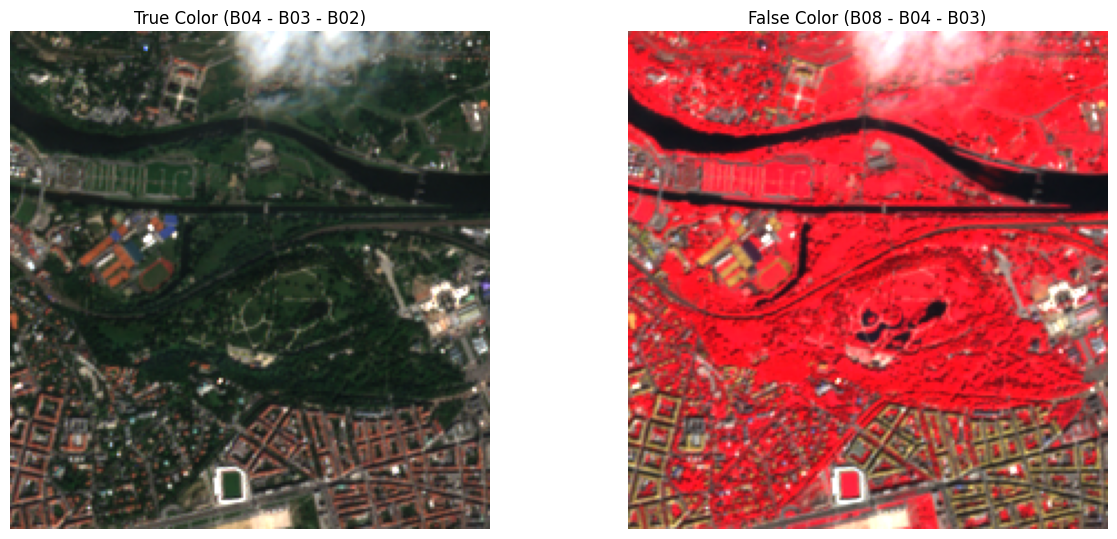

In [11]:
# Vykreslení kompozic True Color a False Color vedle sebe
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))

ax1.imshow(rgb_vis)
ax1.set_title("True Color (B04 - B03 - B02)")
ax1.axis("off")

ax2.imshow(cir_vis)
ax2.set_title("False Color (B08 - B04 - B03)")
ax2.axis("off")

plt.tight_layout()
plt.show()

## 5. Maskování oblačnosti (`SCL`) a indexy NDVI a NDBI

Vrstvu **SCL** použijeme k vyřazení nedefinovaných pixelů (`0`, `1`), stínů mraků (`3`), oblaků (`8`, `9`) a cirkusů (`10`). Nad platnými pixely spočítáme dva indexy:
- **NDVI** = `(B08 - B04) / (B08 + B04)` pro zvýraznění vegetace,
- **NDBI** = `(B11 - B08) / (B11 + B08)` (*Normalized Difference Built-up Index*) pro zvýraznění zastavěných a zpevněných ploch.

In [12]:
# Maskování rušivých kategorií ve vrstvě SCL a výpočet indexů NDVI a NDBI
neplatne_kody = [0, 1, 3, 8, 9, 10]
platne = ~np.isin(scl, neplatne_kody)

def normalizovany_index(a, b, maska):
    soucet = a + b
    vystup = np.full(a.shape, np.nan, dtype="float32")
    ok = maska & (np.abs(soucet) > 1e-6)
    vystup[ok] = (a[ok] - b[ok]) / soucet[ok]
    return vystup

ndvi = normalizovany_index(b08, b04, platne)
ndbi = normalizovany_index(b11, b08, platne)

print(f"Platné pixely: {np.mean(platne) * 100:.1f} %")
print(f"NDVI (min / medián / max): {np.nanmin(ndvi):.2f} / {np.nanmedian(ndvi):.2f} / {np.nanmax(ndvi):.2f}")
print(f"NDBI (min / medián / max): {np.nanmin(ndbi):.2f} / {np.nanmedian(ndbi):.2f} / {np.nanmax(ndbi):.2f}")

Platné pixely: 96.8 %
NDVI (min / medián / max): -0.25 / 0.59 / 0.92
NDBI (min / medián / max): -0.66 / -0.16 / 0.59


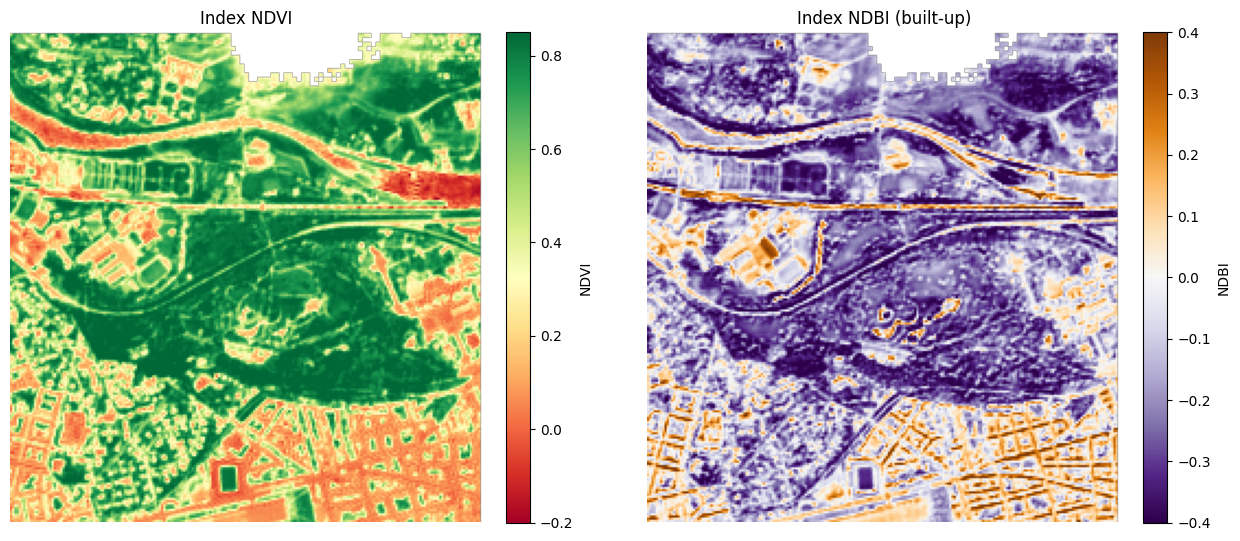

In [13]:
# Vykreslení prostorových map indexů NDVI a NDBI
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))

im1 = ax1.imshow(ndvi, cmap="RdYlGn", vmin=-0.2, vmax=0.85)
ax1.set_title("Index NDVI")
ax1.axis("off")
plt.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04, label="NDVI")

im2 = ax2.imshow(ndbi, cmap="PuOr_r", vmin=-0.4, vmax=0.4)
ax2.set_title("Index NDBI (built-up)")
ax2.axis("off")
plt.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04, label="NDBI")

plt.tight_layout()
plt.show()

## 6. Spektrální křivky vybraných povrchů

Porovnáme chování vegetace, zástavby a vody (`SCL == 6`) napříč pěti kalibrovanými pásmy (`B02`, `B03`, `B04`, `B08`, `B11`) na pixelech vybraných podle hodnot indexů **NDVI** a **NDBI**.

In [16]:
# Výběr reprezentativních pixelů a sestavení hodnot napříč pěti pásmy
voda_pix = platne & (scl == 6)
veg_pix = platne & (~voda_pix) & (ndvi > 0.50)
urb_pix = platne & (~voda_pix) & (ndbi > 0.02) & (ndvi < 0.20)

def stredni_souradnice(maska):
    body = np.argwhere(maska)
    if len(body) == 0:
        body = np.argwhere(platne)
    return tuple(body[len(body) // 2])

r_v, c_v = stredni_souradnice(veg_pix)
r_u, c_u = stredni_souradnice(urb_pix)
r_w, c_w = stredni_souradnice(voda_pix)

vlnove_delky = [490, 560, 665, 842, 1610]
popisky_pasem = ["B02", "B03", "B04", "B08", "B11"]

profily = {
    "Vegetace": [b02[r_v, c_v], b03[r_v, c_v], b04[r_v, c_v], b08[r_v, c_v], b11[r_v, c_v]],
    "Zástavba": [b02[r_u, c_u], b03[r_u, c_u], b04[r_u, c_u], b08[r_u, c_u], b11[r_u, c_u]],
    "Voda": [b02[r_w, c_w], b03[r_w, c_w], b04[r_w, c_w], b08[r_w, c_w], b11[r_w, c_w]],
}

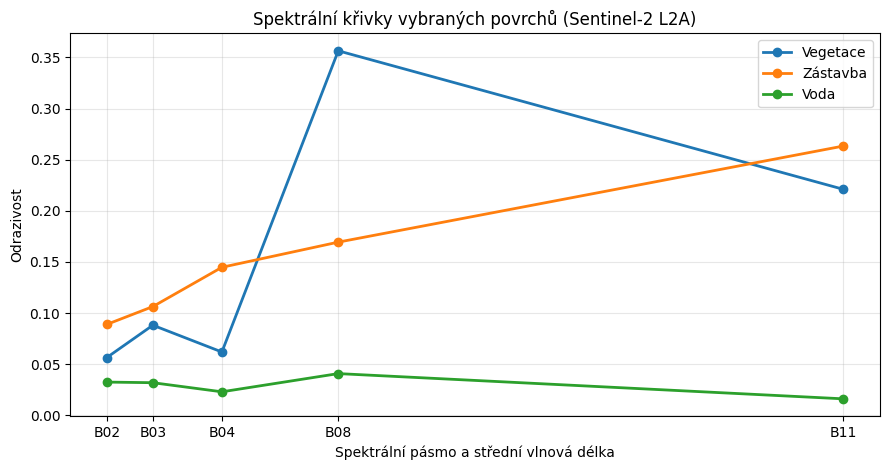

In [17]:
# Vykreslení spektrálních křivek vybraných povrchů
fig, ax = plt.subplots(figsize=(9, 4.8))

for nazev, hodnoty in profily.items():
    ax.plot(vlnove_delky, hodnoty, marker="o", linewidth=2, label=nazev)

ax.set_xticks(vlnove_delky)
ax.set_xticklabels(popisky_pasem)
ax.set_title("Spektrální křivky vybraných povrchů (Sentinel-2 L2A)")
ax.set_xlabel("Spektrální pásmo a střední vlnová délka")
ax.set_ylabel("Odrazivost")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

## 7. Masky vegetace, zástavby a vody

Vytvoříme tři přehledné masky:
- **Maska vegetace**: platné pixely s `NDVI >= 0.35` mimo vodní plochy (`SCL != 6`).
- **Maska vody**: pixely se statusem vodní plochy (`SCL == 6`).
- **Maska zástavby**: platné pixely mimo vegetaci a vodu se zvýšeným indexem `NDBI > -0.05`.

Nakonec je spojíme do souhrnné přehledové vrstvy.

In [18]:
# Tvorba masek vody, vegetace a zástavby a souhrnné klasifikační vrstvy
maska_voda = platne & (scl == 6)
maska_vegetace = platne & (~maska_voda) & (ndvi >= 0.35)
maska_zastavba = platne & (~maska_voda) & (~maska_vegetace) & (ndbi > -0.05)

# 0 = mimo/bez dat, 1 = vegetace, 2 = zástavba, 3 = voda
prehled_trid = np.zeros(b08.shape, dtype="uint8")
prehled_trid[maska_vegetace] = 1
prehled_trid[maska_zastavba] = 2
prehled_trid[maska_voda] = 3

for nazev, m in [
    ("Vegetace", maska_vegetace),
    ("Zástavba", maska_zastavba),
    ("Voda", maska_voda),
]:
    print(f"{nazev:12s}: {np.sum(m):6d} pixelů ({np.mean(m) * 100:5.1f} %)")

Vegetace    :  32212 pixelů ( 66.6 %)
Zástavba    :  10583 pixelů ( 21.9 %)
Voda        :   1054 pixelů (  2.2 %)


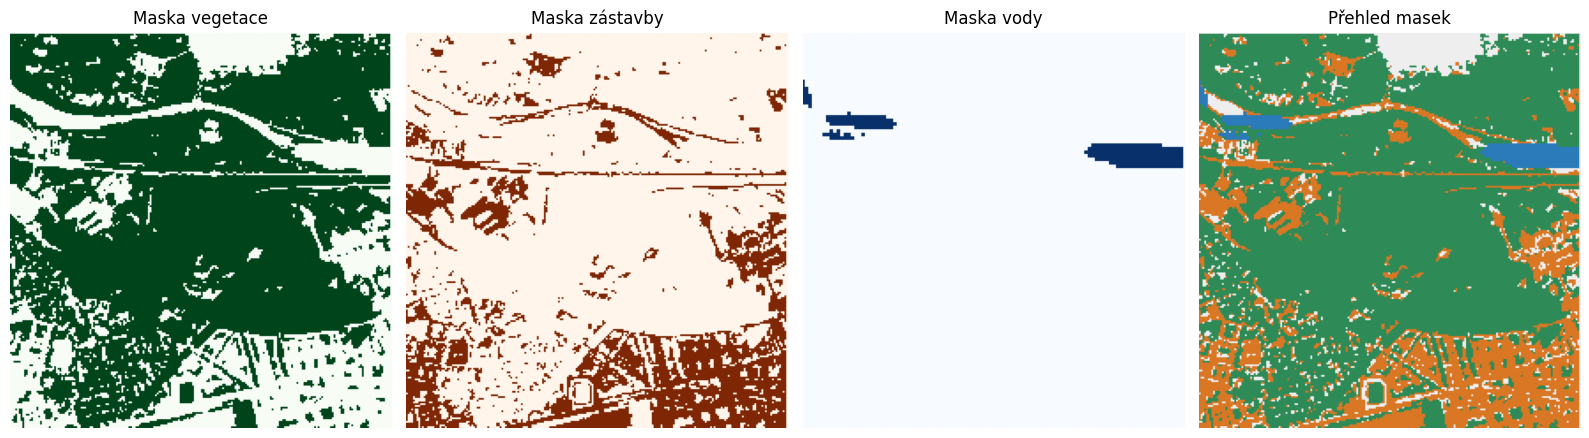

In [19]:
# Vykreslení masek vegetace, zástavby, vody a souhrnného přehledu
fig, axes = plt.subplots(1, 4, figsize=(16, 4.3))

axes[0].imshow(maska_vegetace, cmap="Greens")
axes[0].set_title("Maska vegetace")
axes[0].axis("off")

axes[1].imshow(maska_zastavba, cmap="Oranges")
axes[1].set_title("Maska zástavby")
axes[1].axis("off")

axes[2].imshow(maska_voda, cmap="Blues")
axes[2].set_title("Maska vody")
axes[2].axis("off")

cmap_prehled = ListedColormap(["#eeeeee", "#2e8b57", "#d97724", "#2b7bba"])
axes[3].imshow(prehled_trid, cmap=cmap_prehled, vmin=0, vmax=3)
axes[3].set_title("Přehled masek")
axes[3].axis("off")

plt.tight_layout()
plt.show()

## 8. Porovnání NDVI napříč třídami povrchů a rozloha v území

Na masky vegetace, zástavby a vody navážeme vyhodnocením rozlohy jednotlivých kategorií v hektarech (při 10m rozlišení má jeden pixel `100 m²`, tedy `0,01 ha`) a porovnáme, jak se liší hodnoty **NDVI** uvnitř těchto tříd.

In [22]:
# Výpočet plochy v hektarech a souhrnných statistik NDVI pro jednotlivé třídy povrchů
plocha_pixelu_ha = abs(res_10m[0] * res_10m[1]) / 10000.0

tridy_info = [
    ("Vegetace", maska_vegetace),
    ("Zástavba", maska_zastavba),
    ("Voda", maska_voda),
]

for nazev, maska in tridy_info:
    pocet_px = int(np.sum(maska))
    plocha_ha = pocet_px * plocha_pixelu_ha
    vals = ndvi[maska & (~np.isnan(ndvi))]
    if vals.size > 0:
        print(
            f"{nazev:10s} | {plocha_ha:6.1f} ha | "
            f"NDVI průměr: {np.mean(vals):+.3f} | medián: {np.median(vals):+.3f}"
        )
    else:
        print(f"{nazev:10s} | {plocha_ha:6.1f} ha | bez platných hodnot NDVI")

Vegetace   |  322.1 ha | NDVI průměr: +0.684 | medián: +0.723
Zástavba   |  105.8 ha | NDVI průměr: +0.154 | medián: +0.139
Voda       |   10.5 ha | NDVI průměr: +0.082 | medián: +0.028


/tmp/ipykernel_2814/1927141160.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_box, labels=popisky_box, patch_artist=True, showfliers=False)


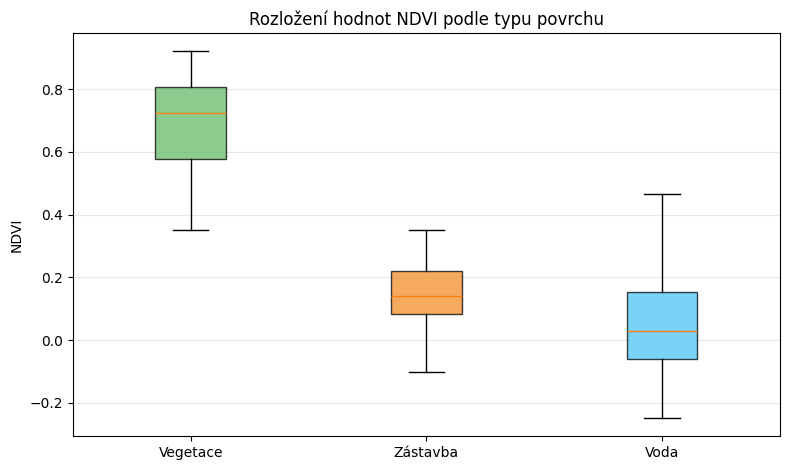

In [23]:
# Vizualizace rozdělení NDVI v jednotlivých třídách povrchů (box-plot)
data_box = []
popisky_box = []

for nazev, maska in tridy_info:
    vals = ndvi[maska & (~np.isnan(ndvi))]
    if vals.size > 0:
        data_box.append(vals)
        popisky_box.append(nazev)

fig, ax = plt.subplots(figsize=(8, 4.8))

bp = ax.boxplot(data_box, labels=popisky_box, patch_artist=True, showfliers=False)
barvy_box = ["#66bb6a", "#f28e2b", "#4fc3f7"]

for patch, barva in zip(bp["boxes"], barvy_box[:len(data_box)]):
    patch.set_facecolor(barva)
    patch.set_alpha(0.75)

ax.set_title("Rozložení hodnot NDVI podle typu povrchu")
ax.set_ylabel("NDVI")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Export georeferencovaného GeoTIFFu a kontrola zápisu

Vytvořený rastr **NDVI** i souhrnnou vrstvu povrchů uložíme do dvoupásmového **GeoTIFFu** (`praha_ndvi_povrchy.tif`) se zachováním souřadnicového systému (`crs`), afinní transformace výřezu (`win_transform_10m`) a hodnoty `NoData`. Na závěr soubor znovu otevřeme v `rasterio` a ověříme jeho metadata.

In [24]:
# Zápis dvoupásmového GeoTIFFu a zpětné ověření metadat v rasterio
vystup_tif = "praha_ndvi_povrchy.tif"
nodata_val = -9999.0

p1_zapis = np.where(np.isnan(ndvi), nodata_val, ndvi).astype("float32")
p2_zapis = přehled_trid.astype("float32") if "přehled_trid" in globals() else prehled_trid.astype("float32")

with rasterio.open(
    vystup_tif,
    "w",
    driver="GTiff",
    height=p1_zapis.shape[0],
    width=p1_zapis.shape[1],
    count=2,
    dtype="float32",
    crs=crs,
    transform=win_transform_10m,
    nodata=nodata_val,
    compress="deflate",
) as dst:
    dst.write(p1_zapis, 1)
    dst.write(p2_zapis, 2)

with rasterio.open(vystup_tif) as src_check:
    print("Uložený soubor:", vystup_tif)
    print("CRS:", src_check.crs)
    print("Počet pásem:", src_check.count)
    print("Rozměry (řádky x sloupce):", src_check.height, src_check.width)
    print("NoData:", src_check.nodata)
    ndvi_overeni = src_check.read(1, masked=True)
    tridy_overeni = src_check.read(2)
    print("Průměr platného NDVI (1. pásmo):", float(ndvi_overeni.mean()))
    print("Unikátní kódy vrstev (2. pásmo):", np.unique(tridy_overeni))

Uložený soubor: praha_ndvi_povrchy.tif
CRS: EPSG:32633
Počet pásem: 2
Rozměry (řádky x sloupce): 224 216
NoData: -9999.0
Průměr platného NDVI (1. pásmo): 0.5197096446185708
Unikátní kódy vrstev (2. pásmo): [0. 1. 2. 3.]
